In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
INK = "#2b2b2b"
MUTED = "#6b6b6b"
GRID = "#ececec"


In [10]:
# ------------------------------------------------------------------ load and clean
df = pd.read_csv("allegations_202007271729.csv")
df = df[["unique_mos_id", "complaint_id", "year_received", "month_received",
         "rank_incident", "rank_now", "board_disposition"]].dropna()  # no drop_duplicates: each row is an allegation
df["substantiated"] = df["board_disposition"].str.startswith("Substantiated")
df = df.sort_values(["unique_mos_id", "year_received", "month_received", "complaint_id"])

# Rank scales.
# ANY    : Detective counts as one step above Police Officer (used by Visualization 1)
# LADDER : Detective counts the same as Police Officer (used by Visualization 2)
ANY = {"Police Officer": 0, "Detective": 1, "Sergeant": 2, "Lieutenant": 3,
       "Captain": 4, "Deputy Inspector": 5, "Inspector": 6, "Chiefs and other ranks": 7}
LADDER = {"Police Officer": 0, "Detective": 0, "Sergeant": 1, "Lieutenant": 2,
          "Captain": 3, "Deputy Inspector": 4, "Inspector": 5, "Chiefs and other ranks": 6}

# ------------------------------------------------------------------ officer table
first = df.groupby("unique_mos_id").first()
off = pd.DataFrame({
    "first_year": first["year_received"],
    "rank_first": first["rank_incident"],
    "rank_now": first["rank_now"],
})
off["promoted_any"] = off["rank_now"].map(ANY) > off["rank_first"].map(ANY)
off["promoted_ladder"] = off["rank_now"].map(LADDER) > off["rank_first"].map(LADDER)

# ------------------------------------------------------------------ officer table
sub = df[df["substantiated"]]                 # already sorted chronologically
first = sub.groupby("unique_mos_id").first()  # first SUBSTANTIATED complaint

off = pd.DataFrame({
    "first_year": first["year_received"],
    "rank_first": first["rank_incident"],
    "rank_now": first["rank_now"],
})
off["promoted_any"] = off["rank_now"].map(ANY) > off["rank_first"].map(ANY)
off["promoted_ladder"] = off["rank_now"].map(LADDER) > off["rank_first"].map(LADDER)

off["n_sub_allegations"] = sub.groupby("unique_mos_id").size()
off["n_sub_complaints"] = sub.groupby("unique_mos_id")["complaint_id"].nunique()
off["cohort"] = (off["first_year"] // 5 * 5).astype(int)
N = len(off)

In [11]:
# ================================================================== VISUALIZATION 1
# Proposition is TRUE: more substantiated misconduct goes with more promotion.
bins = [0, 1, 2, 3, 5, 10_000]
labels = ["1", "2", "3", "4-5", "6+"]
off["alleg_group"] = pd.cut(off["n_sub_allegations"], bins, labels=labels)
v1 = (off.groupby("alleg_group", observed=True)["promoted_any"]
         .agg(rate="mean", n="size").reset_index())

fig, ax = plt.subplots(figsize=(9.5, 6))
x = np.arange(len(v1))
y = v1["rate"].values * 100

# thin connecting line plus dots, so the axis starts at 40% without bars that encode length
ax.plot(x, y, color="#b4182a", lw=2.4, zorder=2, alpha=0.9)
ax.scatter(x, y, s=330, color="#b4182a", zorder=3, edgecolor="white", linewidth=2)
for xi, yi in zip(x, y):
    ax.text(xi, yi + 2.3, f"{yi:.0f}%", ha="center", va="bottom",
            fontsize=15, fontweight="bold", color=INK)

ax.set_xticks(x)
ax.set_xticklabels(v1["alleg_group"], fontsize=13, color=INK)
ax.set_ylim(40, 78)
ax.set_yticks([40, 50, 60, 70])
ax.set_yticklabels([f"{t}%" for t in [40, 50, 60, 70]], fontsize=12, color=MUTED)
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_xlabel("Substantiated misconduct allegations against the officer",
              fontsize=12, color=INK, labelpad=10)
ax.set_ylabel("Share of officers promoted", fontsize=12, color=INK, labelpad=10)

# annotation drawing the eye to the gap
ax.annotate("", xy=(4.28, y[4]), xytext=(4.28, y[0]),
            arrowprops=dict(arrowstyle="<->", color=MUTED, lw=1.4))
ax.text(4.36, (y[0] + y[4]) / 2, f"+{y[4]-y[0]:.0f}\npoints", fontsize=12,
        color=MUTED, va="center", ha="left")
ax.set_xlim(-0.5, 5.0)

fig.text(0.06, 0.945, "More substantiated allegations, more promotions",
         fontsize=20, fontweight="bold", color=INK, ha="left")
fig.text(0.06, 0.895, "Share of NYPD officers promoted, by number of substantiated allegations on record",
         fontsize=13, color=MUTED, ha="left")
fig.text(0.06, 0.045,
         f"Source: NYPD CCRB allegations, through July 2020 (n = {N:,} officers).",
         fontsize=9, color=MUTED, ha="left")
fig.text(0.06, 0.02,
         "Promoted = current rank is above rank at first complaint, including a move to Detective.",
         fontsize=9, color=MUTED, ha="left")
fig.subplots_adjust(top=0.82, bottom=0.19, left=0.09, right=0.96)
fig.savefig("viz1_proposition_true.png", dpi=200)
plt.close(fig)

In [12]:
# ================================================================== VISUALIZATION 2
# Proposition is FALSE: tenure, not misconduct, explains who gets promoted.
off["complaint_group"] = pd.cut(off["n_sub_complaints"], [0, 1, 2, 10_000],
                                labels=["1 complaint", "2 complaints", "3+ complaints"])
v2 = (off.groupby(["cohort", "complaint_group"], observed=True)["promoted_ladder"]
         .agg(rate="mean", n="size").reset_index())
cohorts = sorted(off["cohort"].unique())
cohort_labels = [f"{c}-{str(c + 4)[-2:]}" for c in cohorts]

colors = {"1 complaint": "#9ecae1", "2 complaints": "#3182bd", "3+ complaints": "#08306b"}
offsets = {"1 complaint": -0.2, "2 complaints": 0.0, "3+ complaints": 0.2}

fig, ax = plt.subplots(figsize=(9.5, 6))
for g, c in colors.items():
    d = v2[v2["complaint_group"] == g]
    xs = [cohorts.index(k) + offsets[g] for k in d["cohort"]]
    solid = d["n"] >= 30
    ax.scatter(np.array(xs)[solid], d["rate"][solid] * 100, s=140, color=c,
               zorder=3, edgecolor="white", linewidth=1.5, label=g)
    # hollow markers where fewer than 30 officers, so thin groups don't look as solid
    ax.scatter(np.array(xs)[~solid], d["rate"][~solid] * 100, s=140, facecolor="white",
               edgecolor=c, linewidth=2, zorder=3)

# bracket showing the spread across complaint counts within one cohort vs. across cohorts
by_cohort = v2.groupby("cohort")["rate"].agg(["min", "max"]) * 100
for i, c in enumerate(cohorts):
    ax.plot([i, i], [by_cohort.loc[c, "min"], by_cohort.loc[c, "max"]],
            color="#bdbdbd", lw=6, solid_capstyle="round", zorder=1, alpha=0.7)

ax.set_xticks(range(len(cohorts)))
ax.set_xticklabels(cohort_labels, fontsize=12, color=INK)
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 20))
ax.set_yticklabels([f"{t}%" for t in range(0, 101, 20)], fontsize=12, color=MUTED)
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_xlabel("Year of officer's first complaint (5-year groups)", fontsize=12,
              color=INK, labelpad=10)
ax.set_ylabel("Share of officers promoted", fontsize=12, color=INK, labelpad=10)

ax.annotate("", xy=(0.0, 18), xytext=(0.0, 18))
ax.text(2.55, 90, "Across eras, the drop is about 70 points", fontsize=12,
        color=INK, fontweight="bold", ha="left")
ax.text(2.55, 83, "Within an era, 3+ complaints add roughly 10-15", fontsize=12,
        color=MUTED, ha="left")
ax.text(2.55, 77.5, "points over a single complaint", fontsize=12, color=MUTED, ha="left")

handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=10, label=g)
           for g, c in colors.items()]
handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="white",
                      markeredgecolor=MUTED, markersize=10, label="fewer than 30 officers"))
ax.legend(handles=handles, loc="lower left", frameon=False, fontsize=10,
          bbox_to_anchor=(0.01, 0.02))

fig.text(0.06, 0.945, "Era matters far more than misconduct in who gets promoted",
         fontsize=18, fontweight="bold", color=INK, ha="left")
fig.text(0.06, 0.895, "Share of NYPD officers promoted, by era of first complaint and number of substantiated complaints",
         fontsize=12, color=MUTED, ha="left")
fig.text(0.06, 0.045,
         f"Source: NYPD CCRB allegations, through July 2020 (n = {N:,} officers).",
         fontsize=9, color=MUTED, ha="left")
fig.text(0.06, 0.02,
         "Promoted = moved up the rank ladder (Detective not counted).",
         fontsize=9, color=MUTED, ha="left")
fig.subplots_adjust(top=0.82, bottom=0.19, left=0.09, right=0.96)
fig.savefig("viz2_proposition_false.png", dpi=200)
plt.close(fig)

print(v2.assign(rate=(v2["rate"] * 100).round(0)).pivot(
    index="cohort", columns="complaint_group", values=["rate", "n"]).to_string())

                       rate                                      n                           
complaint_group 1 complaint 2 complaints 3+ complaints 1 complaint 2 complaints 3+ complaints
cohort                                                                                       
1985                   70.0         50.0         100.0        10.0          2.0           1.0
1990                   53.0         64.0          33.0        30.0         14.0           6.0
1995                   39.0         47.0          77.0       106.0         32.0          13.0
2000                   39.0         42.0          45.0       267.0         57.0          31.0
2005                   28.0         30.0          43.0       559.0        131.0          69.0
2010                   22.0         25.0          33.0       878.0        211.0          73.0
2015                    7.0          5.0          15.0      1338.0        141.0          27.0


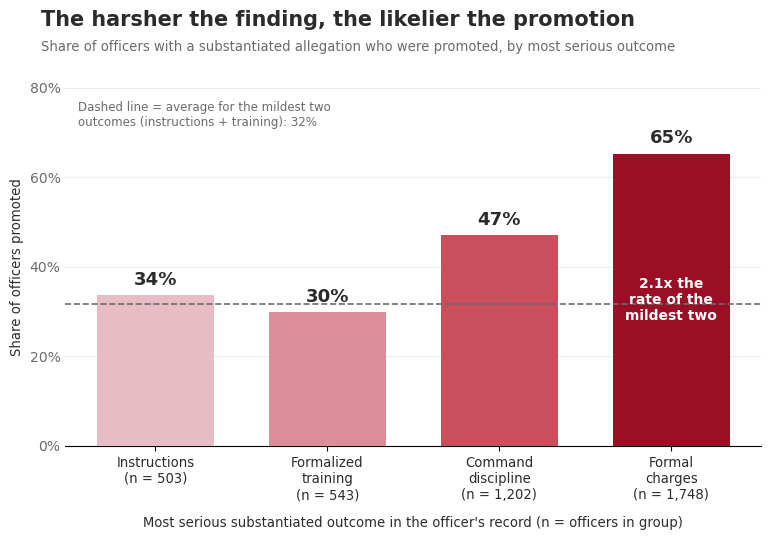

In [13]:
# ---- promotion: rank at first complaint (any outcome) vs. rank now
first = df.groupby("unique_mos_id").first()
off = pd.DataFrame({"promoted": first["rank_now"].map(ANY) > first["rank_incident"].map(ANY)})

# ---- most serious substantiated outcome per officer
TIERS = ["Instructions", "Formalized\ntraining", "Command\ndiscipline", "Formal\ncharges"]
def tier(s):
    if "Charges" in s: return 3
    if "Command Discipline" in s: return 2      # covers A, B and plain
    if "Formalized Training" in s: return 1
    return 0                                     # Instructions, Command Lvl Instructions, No Recommendations

sub = df[df["substantiated"]].copy()
sub["sev"] = sub["board_disposition"].map(tier)
off["worst"] = sub.groupby("unique_mos_id")["sev"].max()
off = off.dropna(subset=["worst"])
off["worst"] = off["worst"].astype(int)

g = off.groupby("worst")["promoted"].agg(rate="mean", n="count")
mild = off[off["worst"] <= 1]["promoted"].mean()    # mildest two combined
ratio = g.loc[3, "rate"] / mild

# ---- chart
colors = ["#e8bcc4", "#d98e98", "#c94f5c", "#9b0f24"]
fig, ax = plt.subplots(figsize=(8, 5.6))
x = np.arange(4)
ax.bar(x, g["rate"]*100, width=0.68, color=colors, zorder=3)
ax.set_ylim(0, 80)
ax.set_yticks(range(0, 81, 20)); ax.set_yticklabels([f"{t}%" for t in range(0, 81, 20)], color=MUTED)
ax.yaxis.grid(True, color=GRID, zorder=0); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

for xi, r in zip(x, g["rate"]):
    ax.text(xi, r*100 + 1.5, f"{r*100:.0f}%", ha="center", va="bottom",
            fontsize=13, fontweight="bold", color=INK)

ax.axhline(mild*100, color=MUTED, ls="--", lw=1.2, zorder=4)
ax.text(-0.45, 77, f"Dashed line = average for the mildest two\noutcomes (instructions + training): {mild*100:.0f}%",
        fontsize=8.5, color=MUTED, va="top")
ax.text(3, g.loc[3, "rate"]*100/2, f"{ratio:.1f}x the\nrate of the\nmildest two",
        ha="center", va="center", color="white", fontsize=10, fontweight="bold", zorder=5)

ax.set_xticks(x)
ax.set_xticklabels([f"{t}\n(n = {n:,})" for t, n in zip(TIERS, g["n"])], fontsize=9.5, color=INK)
ax.set_xlabel("Most serious substantiated outcome in the officer's record (n = officers in group)",
              fontsize=9.5, color=INK, labelpad=10)
ax.set_ylabel("Share of officers promoted", fontsize=9.5, color=INK)

fig.text(0.07, 0.95, "The harsher the finding, the likelier the promotion",
         fontsize=15, fontweight="bold", color=INK, ha="left")
fig.text(0.07, 0.905, "Share of officers with a substantiated allegation who were promoted, by most serious outcome",
         fontsize=9.5, color=MUTED, ha="left")
fig.subplots_adjust(top=0.84, left=0.1, right=0.97, bottom=0.2)
plt.show()

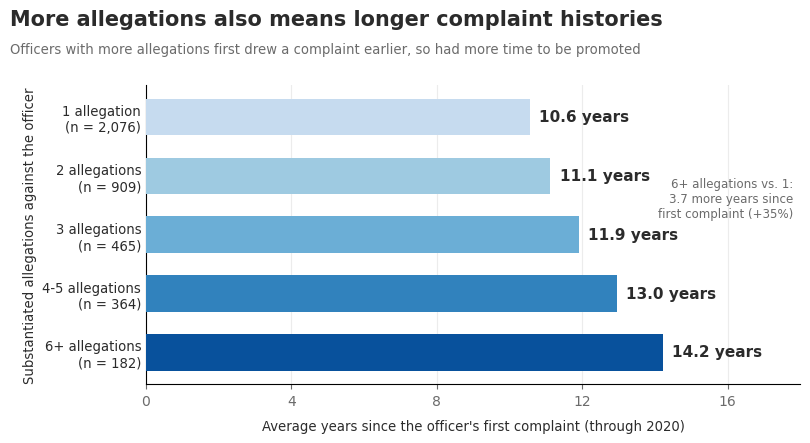

In [14]:
# ---- officer table
sub = df[df["substantiated"]]
off = pd.DataFrame({
    "n_sub_allegations": sub.groupby("unique_mos_id").size(),
    "first_year": df.groupby("unique_mos_id")["year_received"].min(),   # first complaint, any outcome
}).dropna()
off["years_since"] = 2020 - off["first_year"]

labels = ["1", "2", "3", "4-5", "6+"]
off["grp"] = pd.cut(off["n_sub_allegations"], [0, 1, 2, 3, 5, np.inf], labels=labels)

g = off.groupby("grp", observed=True)["years_since"].agg(mean="mean", n="count")
diff = g.loc["6+", "mean"] - g.loc["1", "mean"]
pct = diff / g.loc["1", "mean"] * 100

# ---- chart
blues = ["#c6dbef", "#9ecae1", "#6baed6", "#3182bd", "#08519c"]
ylabs = [f"{l} allegation{'s' if l != '1' else ''}\n(n = {n:,})" for l, n in zip(labels, g["n"])]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
y = np.arange(len(labels))[::-1]
ax.barh(y, g["mean"], height=0.62, color=blues, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(ylabs, fontsize=9.5, color=INK)
ax.set_xlim(0, 18); ax.set_xticks(range(0, 17, 4))
ax.xaxis.grid(True, color=GRID, zorder=0); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", colors=MUTED)

for yi, v in zip(y, g["mean"]):
    ax.text(v + 0.25, yi, f"{v:.1f} years", va="center", fontsize=11, fontweight="bold", color=INK)

ax.text(17.8, 2.6, f"6+ allegations vs. 1:\n{diff:.1f} more years since\nfirst complaint (+{pct:.0f}%)",
        ha="right", va="center", fontsize=8.5, color=MUTED)
ax.set_xlabel("Average years since the officer's first complaint (through 2020)",
              fontsize=9.5, color=INK, labelpad=8)
ax.set_ylabel("Substantiated allegations against the officer", fontsize=9.5, color=INK)

fig.text(0.04, 0.95, "More allegations also means longer complaint histories",
         fontsize=15, fontweight="bold", color=INK, ha="left")
fig.text(0.04, 0.89, "Officers with more allegations first drew a complaint earlier, so had more time to be promoted",
         fontsize=9.5, color=MUTED, ha="left")
fig.subplots_adjust(top=0.82, left=0.2, right=0.97, bottom=0.17)
plt.show()